<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/Phase3_Retrieval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 3 — Embeddings & Retrieval: borrowing tags from similar products
**Tag Recommender Agent roadmap · Weeks 5–6**

### 🎯 The idea in one sentence
To tag a new product, **find the most similar products we already know, and let them vote on the tags.**

**Forecasting analogy — analog forecasting:** to predict tomorrow, find past days whose conditions looked most like today and use what happened after them. Here: to tag a product, find past products whose text looks most like it and use their tags.

### Why this phase, after Phase 2?
Phase 2 ended with three lessons:
1. **TF-IDF ≈ DistilBERT** → a better *text reader* alone didn't help; the limit is the **information in short titles**.
2. **Rare tags often score F1 = 0**, and **implicit tags** (not written in the text) are mostly missed.
3. In Phase 1, **similar texts shared ~8× more tags** than random pairs.

Retrieval brings **new information**: the tags of similar products. A neighbour may carry `Product Benefits=hydrating` even if *your* title never says "hydrating". That's exactly what Phase 2's models couldn't do.

### What you will do
| Section | What | Roadmap task |
|---|---|---|
| 1 | Load Phase 2 data, split and metrics | — |
| 2 | Encode every product as an embedding | 📘 sentence-transformers |
| 3 | Fast similarity search with **FAISS** | 📘 FAISS nearest-neighbour search |
| 4 | **kNN tag propagation** (similar products vote) | 🎯 kNN tag propagation tagger |
| 5 | TF-IDF neighbours vs embedding neighbours | 📊 Compare with Phase 2 baselines |
| 6 | **Hybrid**: Baseline 1 + kNN together | 📊 |
| 7 | Leakage check: why the vendor split matters *most* here | — |
| 8 | Where does retrieval help? rare tags · implicit tags | — |
| 9 | Final scoreboard · 10 Explainability · 11 Save · 12 Summary | — |

### The bar to beat (Phase 2, test set)
**P@3 0.47 · micro-F1 0.56 · macro-F1 0.31 · MAP 0.67**

> **Runtime:** `Runtime → Change runtime type → T4 GPU` (encoding is ~10× faster on GPU; everything else runs on CPU).

## 0 · Setup

In [1]:
!pip -q install -U sentence-transformers faiss-cpu

In [2]:
import json, re, os, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_colwidth", 100)
np.random.seed(42)
BLUE, GRAY, ORANGE, INK = "#2a6fdb", "#9aa0a6", "#e8710a", "#222222"

## 1 · Load everything from Phase 2
**Why:** a fair comparison needs **the same products, the same tags, the same vendor split and the same metrics** as Phase 2. So we don't rebuild anything — we load what Phase 2 saved.

| File (in `MyDrive/tag_agent/phase2/`) | What it is |
|---|---|
| `All_Beauty_phase2.pkl` | products: text, tags, split, text-length group |
| `Y.npy` | the 0/1 tag matrix (products × tags) |
| `tags.json` | the column names of Y |
| `split.csv` | train / val / test + vendor of each product |
| `results.json` | Phase 2 test scores (for the final scoreboard) |

In [3]:
from google.colab import drive
drive.mount("/content/drive")
DIR = "/content/drive/MyDrive/tag_agent"

Mounted at /content/drive


In [4]:
CATEGORY = "All_Beauty"
IN, OUT = f"{DIR}/phase2", f"{DIR}/phase3"
os.makedirs(OUT, exist_ok=True)

data  = pd.read_pickle(f"{IN}/{CATEGORY}_phase2.pkl")
Y     = np.load(f"{IN}/Y.npy")
TAGS  = np.array(json.load(open(f"{IN}/tags.json")))
split = pd.read_csv(f"{IN}/split.csv")
assert (split["parent_asin"].values == data["parent_asin"].values).all(), "row order mismatch: rerun Phase 2"
data["vendor"] = split["vendor"].values
phase2 = json.load(open(f"{IN}/results.json"))

m_tr, m_va, m_te = [(data["split"] == s).values for s in ("train", "val", "test")]
Y_tr, Y_va, Y_te = Y[m_tr], Y[m_va], Y[m_te]
TAG_ATTR = np.array([t.split("=")[0] for t in TAGS])
texts = data["clean"].values

print(f"Products: {len(data):,} | tags: {len(TAGS)} | train {m_tr.sum():,} · val {m_va.sum():,} · test {m_te.sum():,}")

Products: 19,401 | tags: 211 | train 13,702 · val 2,716 · test 2,983


### Same metric functions as Phase 2
Copied unchanged — if the scoring code changed, the comparison would be meaningless.

In [5]:
from sklearn.metrics import f1_score, average_precision_score, ndcg_score

def at_k(Yt, S, k):
    topk = np.argsort(-S, axis=1)[:, :k]
    hits = np.take_along_axis(Yt, topk, axis=1).sum(1)
    return float((hits / k).mean()), float((hits / Yt.sum(1)).mean())

def binarize(S, thr, at_least_one=True):
    P = (S >= thr).astype(int)
    if at_least_one:
        empty = P.sum(1) == 0
        P[empty, S[empty].argmax(1)] = 1
    return P

def evaluate(Yt, S, thr=0.5):
    P = binarize(S, thr)
    present = np.flatnonzero(Yt.sum(0) > 0)
    p3, r3 = at_k(Yt, S, 3); p5, r5 = at_k(Yt, S, 5)
    return {"micro-F1": f1_score(Yt, P, average="micro", zero_division=0),
            "macro-F1": f1_score(Yt, P, average="macro", labels=present, zero_division=0),
            "P@3": p3, "R@3": r3, "P@5": p5, "R@5": r5,
            "MAP": average_precision_score(Yt, S, average="samples"),
            "NDCG@5": ndcg_score(Yt, S, k=5)}

def tune_threshold(Yv, Sv):
    grid = np.round(np.arange(0.05, 0.95, 0.05), 2)
    f1s = [f1_score(Yv, binarize(Sv, g), average="micro", zero_division=0) for g in grid]
    return float(grid[int(np.argmax(f1s))])

results = {name: r for name, r in phase2["results_test"].items()}   # Phase 2 rows of the scoreboard
pd.DataFrame(results).T.round(3)

,micro-F1,macro-F1,P@3,R@3,P@5,R@5,MAP,NDCG@5
Popularity,0.152,0.007,0.134,0.147,0.121,0.226,0.198,0.186
TF-IDF + LR,0.579,0.306,0.463,0.655,0.335,0.768,0.683,0.712
DistilBERT,0.589,0.318,0.463,0.651,0.334,0.759,0.686,0.712


## 2 · Turn every product into an embedding 📘
**Why now:** to find "similar products" we need to **measure similarity between texts**. Phase 1 showed two options: TF-IDF (shared *words*) and embeddings (shared *meaning*). We start with embeddings; Section 5 compares both.

### The model: `all-MiniLM-L6-v2`
- A **small Transformer encoder** (BERT family): **6 layers, 384 dimensions, ~22M parameters** (DistilBERT: 66M). Fast enough for every product.
- **Trained for similarity:** its creators trained it on **1B+ pairs of related sentences** with **contrastive learning**: vectors of related sentences are pulled **together**, unrelated ones pushed **apart** → "close vectors" = "similar meaning".
- **Used as-is (frozen):** unlike DistilBERT in Phase 2, we **don't train it** on our tags; it's a ready-made similarity tool.
- Reads up to **256 word pieces** (our titles: mostly < 40).

### How a text becomes one vector (4 steps)
1. **Tokenize** → word pieces → IDs
2. **Transformer** → one 384-number vector **per word piece**, each aware of the whole sentence
3. **Mean pooling** → average them → **one 384-number vector per product**
4. **Normalize** to length 1 → **dot product = cosine similarity** (1 = same meaning, 0 = unrelated); FAISS needs this in Section 3

| Text | → | Embedding (384 numbers) |
|---|---|---|
| "Hydrating cream for dry skin" | → | [0.12, −0.03, 0.41, …] |
| "Moisturizing lotion, very dry skin" | → | [0.10, −0.01, 0.39, …] ← close |
| "Curly human hair wig" | → | [−0.22, 0.31, −0.05, …] ← far |
*(numbers illustrative)*

*Forecasting analogy:* like an encoder pretrained to summarise each day's weather as one feature vector, so "similar days" can be found by distance, used without retraining.

In [6]:
from sentence_transformers import SentenceTransformer

EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
encoder = SentenceTransformer(EMB_MODEL)

t0 = time.time()
E = encoder.encode(list(texts), batch_size=256, show_progress_bar=True,
                   normalize_embeddings=True, convert_to_numpy=True).astype("float32")
print(f"Embeddings: {E.shape} in {time.time() - t0:.0f}s | vector length of row 0 = {np.linalg.norm(E[0]):.3f}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/76 [00:00<?, ?it/s]

Embeddings: (19401, 384) in 17s | vector length of row 0 = 1.000


**Check:** shape = (products, 384) and vector length = 1.000 (normalized).

## 3 · Fast similarity search with FAISS 📘
**The problem:** for each of ~2,900 test products we must compare it with ~13,500 train products → ~39 million similarity scores. Fine here, but real marketplaces have **millions** of products.

**FAISS** (Facebook AI Similarity Search) is a library built for exactly this: give it a set of vectors (the **index**), then ask *"which k vectors are most similar to this one?"* — very fast.

**Three steps:**
1. **Create an index** → `IndexFlatIP(384)`: "Flat" = exact search (checks every vector, no approximation); "IP" = inner product (= cosine, since vectors are normalized)
2. **Add the train embeddings** → the "library" of known products
3. **Search** → for each query, returns the **similarities** and **row numbers** of its k nearest train products

⚠️ **Only train products go into the index.** Val/test products are queries, never neighbours — otherwise a product could borrow tags from another test product (leakage).

*Forecasting analogy:* the index = your archive of past days; search = "find the 50 past days most like today".

### 💡 Cosine vs FAISS: not either/or
- **Cosine similarity = *what* "similar" means.** Vectors are normalized, so the inner product (the "IP" in `IndexFlatIP`) **is** the cosine.
- **FAISS = *how* we find the most similar products fast:** it computes the cosines and **keeps only the top-k** per query.
- **Without FAISS:** compute the full `E_te @ E_tr.T` (2,983 × 13,702 ≈ 41M numbers) and sort every row yourself → same result, much slower at marketplace scale.

In [8]:
import faiss

E_tr, E_va, E_te = E[m_tr], E[m_va], E[m_te]
index = faiss.IndexFlatIP(E.shape[1])
index.add(E_tr)
print("Products in the index (train only):", index.ntotal)

K_MAX = 50
sim_va, idx_va = index.search(E_va, K_MAX)
sim_te, idx_te = index.search(E_te, K_MAX)
print("For each query →", sim_te.shape, "similarities and", idx_te.shape, "neighbour row numbers (sorted, best first)")

Products in the index (train only): 13702
For each query → (2983, 50) similarities and (2983, 50) neighbour row numbers (sorted, best first)


### Look at one product and its neighbours
**Goal:** before building anything on top of neighbours, check with your own eyes that they make sense.

In [9]:
tr_df, te_df = data[m_tr].reset_index(drop=True), data[m_te].reset_index(drop=True)

def show_neighbours(i, k=5):
    print(f"▶ TEST PRODUCT: {te_df.loc[i, 'title_txt'][:100]}")
    print(f"  true tags: {', '.join(te_df.loc[i, 'tags'])}\n")
    rows = [{"similarity": round(float(sim_te[i, r]), 3),
             "neighbour (train)": tr_df.loc[idx_te[i, r], "title_txt"][:70],
             "its tags": ", ".join(tr_df.loc[idx_te[i, r], "tags"])} for r in range(k)]
    return pd.DataFrame(rows)

show_neighbours(0)

▶ TEST PRODUCT: Stain Bonnet For Baby Bonnet Silk Sleep Cap For Toddler Child Shower Cap Teens Kids
  true tags: Material=silk



,similarity,neighbour (train),its tags
0,0.684,Satin Bonnet Silk Bonnet for Sleeping Silk Sleep Cap Hair Bonnet for S,Item Form=cream
1,0.660,Satin Bonnet Silk Sleep Cap for Women Long Curly Hair - Night Hat Head,Material=silk
2,0.657,"Wide Band Kids Satin Bonnet,Stretchable Sleeping Cap Silky Night Hats","Age Range (Description)=kid, Color=pink, Material=satin"
3,0.639,2pcs Non-slip Elastic Silk Bonnet Sleep Cap for Woman Girl Curly Long,Material=silk
4,0.621,"Shower Cap for Women Long Hair, Hair Cap Bonnet for Curly Hair Baby Sl",Material=satin


**What to look for:** are the neighbours the **same kind of product**? Do their tags overlap with the true tags? Try a few: `show_neighbours(5)`, `show_neighbours(42)`.

## 4 · kNN tag propagation: similar products vote 🎯
**The rule:** a tag's score = the **similarity-weighted share** of the k neighbours that have it.

**Worked example** — a test product with 3 neighbours:

| neighbour | similarity | has `Skin Type=dry`? |
|---|---|---|
| A | 0.90 | ✅ |
| B | 0.80 | ✅ |
| C | 0.50 | ❌ |

- **Plain vote:** 2 of 3 neighbours → 0.67
- **Similarity-weighted:** (0.90 + 0.80) / (0.90 + 0.80 + 0.50) = **0.77** → closer neighbours count more

**Two settings to tune on validation:**
- **k** = how many neighbours vote (5, 10, 20, 50). Too few → noisy; too many → far, unrelated products join in.
- **power p** = sharpen the weights: similarity^p. With p = 3: 0.9³ = 0.73 vs 0.5³ = 0.13 → the closest neighbours dominate.

Like Phase 2 models, the result is a **score matrix S** (products × tags), so the same metrics apply.

In [11]:
Y_tr32 = Y_tr.astype("float32")

def knn_scores(sims, idxs, k=20, power=3, Y_index=Y_tr32):
    w = np.clip(sims[:, :k], 0, None) ** power                 # (n, k) weights
    votes = Y_index[idxs[:, :k]]                                # (n, k, tags) neighbours' 0/1 tags
    return (w[:, :, None] * votes).sum(1) / (w.sum(1, keepdims=True) + 1e-9)

# check the worked example: similarities 0.9, 0.8, 0.5; tags 1, 1, 0; power 1
demo = knn_scores(np.array([[0.9, 0.8, 0.5]]), np.array([[0, 1, 2]]), k=3, power=1,
                  Y_index=np.array([[1], [1], [0]], dtype="float32"))
print("Worked example score:", demo.round(2))       # should be 0.77

Worked example score: [[0.77]]


### Tune k and power on validation
We try every combination and keep the best **validation P@3** — the test set stays untouched until the very end.

In [12]:
grid = []
for k in [5, 10, 20, 50]:
    for p in [1, 3, 5]:
        grid.append({"k": k, "power": p, "val P@3": at_k(Y_va, knn_scores(sim_va, idx_va, k, p), 3)[0]})
grid = pd.DataFrame(grid)
best = grid.loc[grid["val P@3"].idxmax()]
K_BEST, P_BEST = int(best["k"]), int(best["power"])
print(f"Best: k = {K_BEST}, power = {P_BEST}  (val P@3 = {best['val P@3']:.3f})")
grid.pivot(index="k", columns="power", values="val P@3").round(3)

Best: k = 50, power = 5  (val P@3 = 0.401)


power,1,3,5
k,,,
5,0.372,0.372,0.372
10,0.389,0.389,0.390
20,0.398,0.399,0.400
50,0.393,0.397,0.401


**How to read the grid:** rows = k, columns = power, cells = validation P@3. Look for the pattern: does more k help or hurt? Does sharpening (higher power) help when k is large?
⚠️ If the best k is the **largest** value tried (50), the optimum may be beyond the grid → try `K_MAX = 100` and add 100 to the list.

### 📊 Result: tuning k and power (validation P@3)
- **k matters:** 5 → 0.372 · 10 → 0.389 · **20 → 0.400** · 50 → ~0.40 → more voters = more stable; levels off after ~20.
- **Power barely matters** (≤ 0.008): a product's neighbours have similar similarities (e.g. 0.62–0.68), so sharpening changes little.
- **Best: k = 50, power = 5 (0.401)**, practically equal to k = 20 (0.400) → the curve has flattened; no need to try larger k.
- **Expectation:** val P@3 ≈ 0.40 < TF-IDF + LR (0.47) → kNN alone likely won't win; its value is the **different information** → check the **hybrid** (Section 6) and **rare/implicit tags** (Section 8).

In [13]:
S_va_knn = knn_scores(sim_va, idx_va, K_BEST, P_BEST)
S_te_knn = knn_scores(sim_te, idx_te, K_BEST, P_BEST)
thr_knn = tune_threshold(Y_va, S_va_knn)
results["kNN (embeddings)"] = evaluate(Y_te, S_te_knn, thr_knn)
pd.DataFrame(results).T.round(3)

,micro-F1,macro-F1,P@3,R@3,P@5,R@5,MAP,NDCG@5
Popularity,0.152,0.007,0.134,0.147,0.121,0.226,0.198,0.186
TF-IDF + LR,0.579,0.306,0.463,0.655,0.335,0.768,0.683,0.712
DistilBERT,0.589,0.318,0.463,0.651,0.334,0.759,0.686,0.712
kNN (embeddings),0.526,0.266,0.418,0.584,0.313,0.711,0.613,0.644


### 💡 The retrieval tagger in one picture
**Concept:** *a product gets the tags that its most similar known products have.*

1. **Embed:** `all-MiniLM-L6-v2` turns each text into 384 numbers (frozen, not trained by us)
2. **Find neighbours:** **FAISS** finds the most similar **train** products (cosine similarity)
3. **Vote (kNN):** neighbours vote with their tags, weighted by similarity → tag scores → top-3

**kNN is a "memory-based" model:** no weights, no training loop, no loss. It **remembers all train products** and looks them up; only **k** and **power** are tuned on validation.

| | TF-IDF + LR | kNN |
|---|---|---|
| Learns | **rules**: "the word *curly* → `Hair Type=curly`" | nothing: copies **examples** |
| Predicts by | weighted words in the text | tags of the most similar products |
| Forecasting analogy | regression model | **analog forecasting**: "today looks like these 20 past days" |

## 5 · Which neighbours are better: by meaning or by words?
**Goal:** keep the **same model (kNN voting)** and change **only the embedding**, i.e. how texts become vectors and therefore who counts as a "similar product".

| Approach | Text → vector (embedding) | How neighbours are found | Model |
|---|---|---|---|
| **kNN (embeddings)**, Section 4 | `all-MiniLM-L6-v2` → 384 dense numbers = **meaning** | FAISS, cosine | **kNN voting** |
| **kNN (TF-IDF)**, this section | **TF-IDF** → ~76k sparse word weights = **words** | `sparse_topk`, cosine | **kNN voting** (same) |
| *TF-IDF + LR*, Baseline 1 (rebuilt here) | **TF-IDF** (same as above) | — (no neighbours) | **Logistic regression**, one per tag |

**Same model, different embedding:**
- **MiniLM** neighbours → similar **meaning** ("hydrating lotion" ≈ "moisturizing cream")
- **TF-IDF** neighbours → similar **words** (exact brands, materials, "human hair 12 inch")

**Why test this?** In Phase 1 the evidence was mixed: MiniLM won one search example (4/5 vs 1/5), but **on average** both found neighbours with similar tags (0.297 vs 0.294). Now: which makes the **better tagger**?

### What the code does (2 jobs)
1. **kNN (TF-IDF):** TF-IDF vectors (fit on train) → each val/test product's 50 most similar **train** products by cosine → **same voting rule** → tune k and power on validation → new scoreboard row.
   *No FAISS here:* TF-IDF vectors are **sparse** (almost all zeros), so `sparse_topk` computes cosine directly, in chunks of 1,000 products.
2. **Rebuild Baseline 1 (TF-IDF + LR), ~1 min:** not a new experiment; Section 6 needs its **validation scores** to combine LR with kNN.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.5,
                        max_features=100_000, sublinear_tf=True)
X_tr = tfidf.fit_transform(texts[m_tr])
X_va, X_te = tfidf.transform(texts[m_va]), tfidf.transform(texts[m_te])

def sparse_topk(Q, X, k=K_MAX, chunk=1000):
    # exact cosine top-k for sparse TF-IDF rows (rows are already length-normalised)
    sims, idxs = [], []
    for s in range(0, Q.shape[0], chunk):
        D = (Q[s:s + chunk] @ X.T).toarray()
        top = np.argpartition(-D, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(D, top, 1), axis=1)
        top = np.take_along_axis(top, order, 1)
        idxs.append(top); sims.append(np.take_along_axis(D, top, 1))
    return np.vstack(sims).astype("float32"), np.vstack(idxs)

tsim_va, tidx_va = sparse_topk(X_va, X_tr)
tsim_te, tidx_te = sparse_topk(X_te, X_tr)

tgrid = [(k, p, at_k(Y_va, knn_scores(tsim_va, tidx_va, k, p), 3)[0]) for k in [5, 10, 20, 50] for p in [1, 3, 5]]
TK, TP, tbest = max(tgrid, key=lambda r: r[2])
S_va_tknn, S_te_tknn = knn_scores(tsim_va, tidx_va, TK, TP), knn_scores(tsim_te, tidx_te, TK, TP)
results["kNN (TF-IDF)"] = evaluate(Y_te, S_te_tknn, tune_threshold(Y_va, S_va_tknn))
print(f"TF-IDF kNN best: k = {TK}, power = {TP} (val P@3 = {tbest:.3f})")

t0 = time.time()
lr = OneVsRestClassifier(LogisticRegression(C=4.0, solver="liblinear", max_iter=1000), n_jobs=-1).fit(X_tr, Y_tr)
S_va_lr, S_te_lr = lr.predict_proba(X_va), lr.predict_proba(X_te)
thr_lr = tune_threshold(Y_va, S_va_lr)
print(f"Baseline 1 rebuilt in {time.time() - t0:.0f}s")
pd.DataFrame(results).T.round(3)

TF-IDF kNN best: k = 50, power = 1 (val P@3 = 0.409)
Baseline 1 rebuilt in 50s


,micro-F1,macro-F1,P@3,R@3,P@5,R@5,MAP,NDCG@5
Popularity,0.152,0.007,0.134,0.147,0.121,0.226,0.198,0.186
TF-IDF + LR,0.579,0.306,0.463,0.655,0.335,0.768,0.683,0.712
DistilBERT,0.589,0.318,0.463,0.651,0.334,0.759,0.686,0.712
kNN (embeddings),0.526,0.266,0.418,0.584,0.313,0.711,0.613,0.644
kNN (TF-IDF),0.541,0.269,0.430,0.603,0.320,0.729,0.634,0.666


**How to read it:** compare the two kNN rows with each other, then with **TF-IDF + LR**. If one kind of neighbour wins clearly, that's the similarity to use in the agent's retrieval tool (Phase 6).

### 📊 Result: words vs meaning for finding neighbours

- **TF-IDF neighbours beat MiniLM neighbours slightly:** P@3 0.430 vs 0.418 · micro-F1 0.541 vs 0.526 · MAP 0.634 vs 0.613.
  → Titles are **keyword lists**; sharing **exact words** (brand, product line, material) identifies truly similar products. Same lesson as TF-IDF ≈ DistilBERT.
- **Both kNN variants are below TF-IDF + LR** (P@3 0.43 vs 0.46, macro-F1 0.27 vs 0.31): copying neighbours' tags is noisier than learning word → tag rules from all products, and neighbours bring their label noise.
- **Best TF-IDF kNN: k = 50, power = 1**: TF-IDF similarities are more spread out, so sharpening doesn't help.
- **Next:** kNN uses *different* information → does **LR + kNN together** (Section 6) beat LR alone?

## 6 · Hybrid: combine Baseline 1 and kNN
**Goal:** average two **finished** models that use **different information**; no new training, only one weight α is tuned.

| Part | Embedding (text → vector) | Model | Uses… |
|---|---|---|---|
| **A** | **TF-IDF** (sparse word weights) | **Logistic regression** ×214 (One-vs-Rest) | word → tag **rules** from all of train → strong for tags **written in the text** |
| **B** | **MiniLM** `all-MiniLM-L6-v2` (384 dense numbers) | **kNN voting** (Section 4) | **tags of similar products** → can find tags **not written** (implicit) |

**Rule (per product, per tag):** S_hybrid = **α · S_LR + (1 − α) · S_kNN**
*Example:* tag `silk`: LR 0.70, kNN 0.40, α = 0.6 → 0.6×0.70 + 0.4×0.40 = **0.58**
α is tuned on validation (α = 1 → only LR, α = 0 → only kNN).

**Why it can work:** A and B differ in **both** embedding (words vs meaning) and model (rules vs neighbours) → they make **different mistakes** → the average can beat both.
*Forecasting analogy:* an **ensemble forecast**: a statistical model blended with an analog forecast.

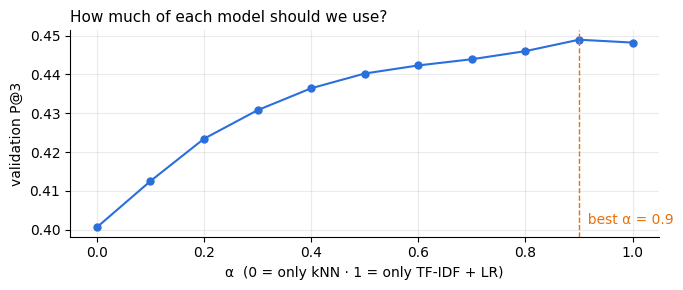

,micro-F1,macro-F1,P@3,R@3,P@5,R@5,MAP,NDCG@5
Popularity,0.152,0.007,0.134,0.147,0.121,0.226,0.198,0.186
TF-IDF + LR,0.579,0.306,0.463,0.655,0.335,0.768,0.683,0.712
DistilBERT,0.589,0.318,0.463,0.651,0.334,0.759,0.686,0.712
kNN (embeddings),0.526,0.266,0.418,0.584,0.313,0.711,0.613,0.644
kNN (TF-IDF),0.541,0.269,0.430,0.603,0.320,0.729,0.634,0.666
Hybrid (LR + kNN),0.580,0.304,0.465,0.659,0.336,0.768,0.687,0.713


In [15]:
alphas = np.round(np.arange(0, 1.01, 0.1), 1)
a_scores = [at_k(Y_va, a * S_va_lr + (1 - a) * S_va_knn, 3)[0] for a in alphas]
ALPHA = float(alphas[int(np.argmax(a_scores))])

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(alphas, a_scores, "-o", color=BLUE, ms=5)
ax.axvline(ALPHA, color=ORANGE, ls="--", lw=1)
ax.text(ALPHA, min(a_scores), f"  best α = {ALPHA}", color=ORANGE, va="bottom")
ax.set_xlabel("α  (0 = only kNN · 1 = only TF-IDF + LR)"); ax.set_ylabel("validation P@3")
ax.set_title("How much of each model should we use?", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

S_va_hyb = ALPHA * S_va_lr + (1 - ALPHA) * S_va_knn
S_te_hyb = ALPHA * S_te_lr + (1 - ALPHA) * S_te_knn
thr_hyb = tune_threshold(Y_va, S_va_hyb)
results["Hybrid (LR + kNN)"] = evaluate(Y_te, S_te_hyb, thr_hyb)
pd.DataFrame(results).T.round(3)

**How to read the curve:** if the best α is in the **middle** (not 0 or 1), the two models really complement each other. The height difference between the ends and the peak = what the combination adds.

### 📊 Result: hybrid (TF-IDF + LR & MiniLM kNN)
- **Curve:** validation P@3 rises from 0.400 (only kNN) to **0.449 at α = 0.9** vs 0.448 at α = 1 (only LR) → **+0.001**.
- **Test:** Hybrid ≈ LR: P@3 0.465 vs 0.463 · micro-F1 0.580 vs 0.579 · macro-F1 0.304 vs 0.306 · MAP 0.687 vs 0.683.
- **Why no gain:** neighbours are found **by text**, so their tags mostly repeat what LR already learned from the same words; neighbours also bring label noise; scores are on different scales.
- **So:** text-based retrieval adds little **new information** → the next gains must come from knowledge **outside the text**: **tag graph** (Phase 4), **LLM reasoning** (Phase 5).
- **Still check Section 8:** the hybrid may help on **rare / implicit** tags even if the average doesn't move.

## 7 · Leakage check: why the vendor split matters *most* for retrieval
**Why:** in Phase 2, a random split inflated TF-IDF + LR only a little (macro-F1 +0.035). We predicted the effect would be **bigger for kNN**, because kNN literally copies the tags of the **most similar product** — and with a random split, that is often the **same vendor's near-identical sibling** ("… 12 inch" in train, "… 14 inch" in test).

**Test:** run the same kNN on a **random** split of the same size and measure:
1. P@3 (random vs vendor split)
2. how often the **top-1 neighbour is from the same vendor**

In [16]:
rng = np.random.default_rng(42)
perm = rng.permutation(len(data))
r_tr, r_te = perm[: m_tr.sum()], perm[m_tr.sum(): m_tr.sum() + m_te.sum()]

idx_r = faiss.IndexFlatIP(E.shape[1]); idx_r.add(E[r_tr])
rsim, ridx = idx_r.search(E[r_te], K_MAX)
S_r = knn_scores(rsim, ridx, K_BEST, P_BEST, Y_index=Y[r_tr].astype("float32"))

vend = data["vendor"].values
same_random = (vend[r_tr][ridx[:, 0]] == vend[r_te]).mean()
same_vendor = (vend[m_tr][idx_te[:, 0]] == vend[m_te]).mean()

pd.DataFrame({"P@3": [at_k(Y[r_te], S_r, 3)[0], results["kNN (embeddings)"]["P@3"]],
              "macro-F1": [evaluate(Y[r_te], S_r, thr_knn)["macro-F1"], results["kNN (embeddings)"]["macro-F1"]],
              "top-1 neighbour from same vendor": [same_random, same_vendor]},
             index=["random split (leaky)", "vendor split (honest)"]).round(3)

,P@3,macro-F1,top-1 neighbour from same vendor
random split (leaky),0.414,0.292,0.278
vendor split (honest),0.418,0.266,0.000


**How to read it:** the vendor split has **0%** same-vendor neighbours by design. If the random split shows a large share **and** a much higher P@3, that extra score is the model **recognising siblings**, not tagging well — exactly the leakage a real marketplace (new vendors, new products) would not give you.

### 📊 Result: leakage check for kNN
- **Random split:** **27.8%** of test products have a **same-vendor sibling** as top-1 neighbour (vendor split: 0%) → the sibling effect is real.
- **But P@3 is not inflated** (0.414 vs 0.418): with **k = 50** voters a sibling is 1 voice in 50; siblings are not always tagged the same; P@3 is driven by common tags.
- **macro-F1 is inflated: +0.026 (~10%)**, same pattern as Phase 2 → **rare tags are often vendor-specific**, and a sibling in train "gives them away".
- **Keep the vendor split:** it removes a ~10% inflation on rare tags. Leakage would be much stronger with **very small k** (1–3).

## 8 · Where does retrieval help?
**Why:** a single overall score hides *where* a method helps. Phase 2 left two weak spots — **rare tags** and **implicit tags**. Does retrieval fix them?

### 8.1 Rare vs common tags
Same buckets as Phase 2's long-tail plot: tags grouped by number of training examples; macro-F1 per bucket.

In [17]:
models = {"TF-IDF + LR": (S_te_lr, thr_lr), "kNN (embeddings)": (S_te_knn, thr_knn), "Hybrid (LR + kNN)": (S_te_hyb, thr_hyb)}
train_count = Y_tr.sum(0)
present = np.flatnonzero(Y_te.sum(0) > 0)
bins = pd.cut(train_count[present], [0, 50, 100, 300, 100_000], labels=["< 50", "50–100", "100–300", "300+"])

rows = {}
for name, (S, thr) in models.items():
    f1 = f1_score(Y_te, binarize(S, thr), average=None, labels=present, zero_division=0)
    rows[name] = pd.Series(f1).groupby(pd.Categorical(bins), observed=False).mean()
by_freq = pd.DataFrame(rows)
by_freq.insert(0, "n_tags", pd.Series(bins).value_counts().reindex(by_freq.index).values)
by_freq = by_freq[by_freq["n_tags"] > 0]
by_freq.round(3)

,n_tags,TF-IDF + LR,kNN (embeddings),Hybrid (LR + kNN)
< 50,85,0.167,0.186,0.163
50–100,55,0.264,0.182,0.264
100–300,50,0.439,0.365,0.441
300+,21,0.658,0.576,0.658


**How to read it:** each row = a group of tags; each column = a model's average F1 on those tags. Compare the **"< 50"** row across models — that's where Phase 2 failed most.

### 📊 Result: rare vs common tags (F1 per frequency group)
- **Long tail is big:** **85 of 211 tags (40%)** have < 50 training examples and score only ~0.17.
- **kNN wins only on the rarest tags:** 0.186 vs 0.167 for LR (**+11%**): LR needs many examples to learn word weights; kNN just copies from a few close neighbours.
- **LR wins everywhere else** (e.g. 300+: 0.658 vs 0.576).
- **Hybrid (α = 0.9) = 90% LR** → loses kNN's rare-tag advantage (0.163).
- **Idea:** a **different α for rare and common tags** (more kNN for rare) → a concrete argument for an **agent that picks its tool per tag**.

### 8.2 Explicit vs implicit tags
**Explicit** = the tag's value is written in the product text ("for **dry** skin" → `Skin Type=dry`). **Implicit** = it is not.
For every (test product, true tag) we check: is the tag in the model's **top-5**? → recall per group.

In [18]:
def contains(value, text):
    return re.search(r"(?<!\w)" + re.escape(value) + r"(?!\w)", text) is not None

low = te_df["clean"].str.lower().values
pairs = [(i, j, contains(TAGS[j].split("=", 1)[1], low[i])) for i in range(len(te_df)) for j in np.flatnonzero(Y_te[i])]
pairs = pd.DataFrame(pairs, columns=["row", "tag", "explicit"])

rows = []
for name, (S, _) in models.items():
    top5 = np.argsort(-S, axis=1)[:, :5]
    hit = [j in top5[i] for i, j in zip(pairs["row"], pairs["tag"])]
    for flag, label in [(True, "explicit (in text)"), (False, "implicit (not in text)")]:
        sel = pairs["explicit"] == flag
        rows.append({"model": name, "tag type": label, "share of true tags": sel.mean(),
                     "found in top-5": np.mean(np.array(hit)[sel.values])})
pd.DataFrame(rows).pivot(index="tag type", columns="model", values="found in top-5").round(3)

model,Hybrid (LR + kNN),TF-IDF + LR,kNN (embeddings)
tag type,,,
explicit (in text),0.848,0.852,0.758
implicit (not in text),0.649,0.640,0.633


**How to read it:** the **implicit** row is the key one for your proposal — those tags can't be read from the text, so any gain there comes from the **new information** retrieval brings (the neighbours' tags).

### 📊 Result: explicit vs implicit tags (share found in top-5)
- **Explicit (in text):** LR **0.852** · Hybrid 0.848 · kNN 0.758 → LR learns word → tag rules directly.
- **Implicit (not in text):** LR 0.640 · kNN 0.633 · Hybrid **0.649** → **kNN does not help** (hybrid +0.009).
- **Surprise:** 64% of implicit tags are found anyway → LR learns **correlations** (e.g. "wig, lace front" → `Material=human hair`).
- **Why no retrieval gain:** neighbours are found **by text**, so their tags have the **same gaps** as the product's.
- **Phase 3 lesson:** text-based retrieval mostly repeats the text; it helps only on the **rarest** tags → remaining implicit tags need **tag-to-tag relations** (Phase 4) and **world knowledge** (Phase 5 LLM).

## 9 · Final scoreboard
**All models, same test set, same metrics.** Gray = popularity floor · blue = Phase 2 baselines · orange = Phase 3 (retrieval).

,micro-F1,macro-F1,P@3,R@3,P@5,R@5,MAP,NDCG@5
Popularity,0.152,0.007,0.134,0.147,0.121,0.226,0.198,0.186
TF-IDF + LR,0.579,0.306,0.463,0.655,0.335,0.768,0.683,0.712
DistilBERT,0.589,0.318,0.463,0.651,0.334,0.759,0.686,0.712
kNN (embeddings),0.526,0.266,0.418,0.584,0.313,0.711,0.613,0.644
kNN (TF-IDF),0.541,0.269,0.430,0.603,0.320,0.729,0.634,0.666
Hybrid (LR + kNN),0.580,0.304,0.465,0.659,0.336,0.768,0.687,0.713


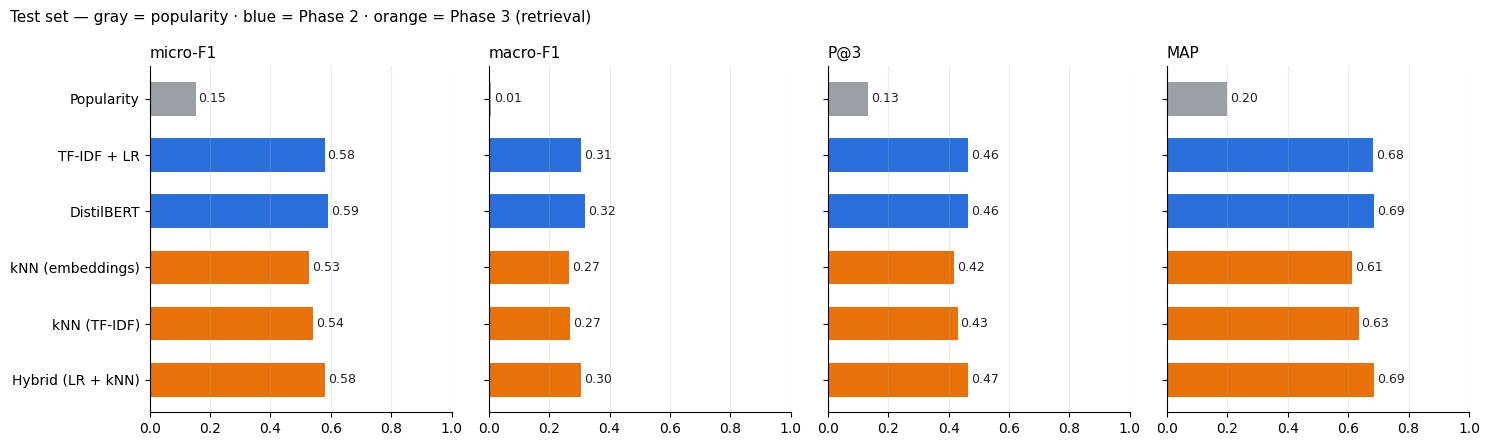

In [19]:
res = pd.DataFrame(results).T
display(res.round(3))

PH3 = {"kNN (embeddings)", "kNN (TF-IDF)", "Hybrid (LR + kNN)"}
colors = [GRAY if n == "Popularity" else ORANGE if n in PH3 else BLUE for n in res.index]
show = ["micro-F1", "macro-F1", "P@3", "MAP"]
fig, axes = plt.subplots(1, len(show), figsize=(15, 0.55 * len(res) + 1.2), sharey=True)
for ax, m in zip(axes, show):
    bars = ax.barh(res.index, res[m], color=colors, height=0.6)
    for b, v in zip(bars, res[m]):
        ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=9, color=INK)
    ax.set_title(m, loc="left", fontsize=11); ax.set_xlim(0, 1)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.25)
axes[0].invert_yaxis()
fig.suptitle("Test set — gray = popularity · blue = Phase 2 · orange = Phase 3 (retrieval)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

### 📊 Final scoreboard (Phase 2 + 3)
- **A ceiling at P@3 ≈ 0.46:** TF-IDF + LR (0.463), DistilBERT (0.463) and Hybrid (0.465) are **tied** (differences ≤ 0.01) → the limit is the **information in short titles**, not the method.
- **Retrieval alone is weaker:** kNN TF-IDF 0.43 · kNN MiniLM 0.42 (P@3); macro-F1 0.27 vs 0.31 for LR.
- **What retrieval adds:** best on the **rarest tags** (+11% F1) and **evidence** for each tag (explainability), but **no overall gain**.
- **Main baseline stays TF-IDF + LR:** same score as DistilBERT/Hybrid at a fraction of the cost.
- **Next:** knowledge **beyond the product text**: tag-to-tag relations (Phase 4), world knowledge (Phase 5 LLM).

## 10 · Explainability: *why* did the model suggest this tag?
**Why this matters for the agent:** a logistic regression can only say "score 0.7". kNN can say **"because these 3 very similar products have this tag"** — real **evidence** a human (or the agent's **verifier** in Phase 6) can check.

In [20]:
def explain(i, n_tags=3, n_neigh=3):
    print(f"▶ {te_df.loc[i, 'title_txt'][:100]}")
    print(f"  true tags: {', '.join(te_df.loc[i, 'tags'])}\n")
    for j in np.argsort(-S_te_hyb[i])[:n_tags]:
        mark = "✅" if Y_te[i, j] else "❌"
        voters = [r for r in range(K_BEST) if Y_tr[idx_te[i, r], j]][:n_neigh]
        print(f"  {mark} {TAGS[j].replace('=', ': ')}   (hybrid score {S_te_hyb[i, j]:.2f})")
        for r in voters:
            print(f"       ← sim {sim_te[i, r]:.2f} · {tr_df.loc[idx_te[i, r], 'title_txt'][:70]}")
        if not voters:
            print("       ← no neighbour has it: suggested by TF-IDF + LR (words in the title)")
    print()

for i in np.random.default_rng(3).choice(len(te_df), 3, replace=False):
    explain(i)

▶ FABA Beauty 9A Grade Human Virgin Hair Bundle Deals Pure 27# Color Body Wave Hair 4 bundles Honey Bl
  true tags: Color=clear, Hair Type=wavy

  ✅ Hair Type: wavy   (hybrid score 0.92)
       ← sim 0.75 · FalaFala 10A Brazilian Body Wave 3 Bundles 16 18 20 Inch 100% Unproces
       ← sim 0.75 · Brazilian Hair Bundles 613 Body Wave Human Hair Bundle 8A Unprocessed 
       ← sim 0.75 · Sakula Ombre Body Wave 2 Tone Virgin Remy Human Hair Bundles with 1b-3
  ❌ Material: human hair   (hybrid score 0.69)
       ← sim 0.75 · FalaFala 10A Brazilian Body Wave 3 Bundles 16 18 20 Inch 100% Unproces
       ← sim 0.75 · Brazilian Hair Bundles 613 Body Wave Human Hair Bundle 8A Unprocessed 
       ← sim 0.75 · Sakula Ombre Body Wave 2 Tone Virgin Remy Human Hair Bundles with 1b-3
  ❌ Material Feature: natural   (hybrid score 0.32)
       ← sim 0.75 · FalaFala 10A Brazilian Body Wave 3 Bundles 16 18 20 Inch 100% Unproces
       ← sim 0.75 · Brazilian Hair Bundles 613 Body Wave Human Hair Bundle 8A

**How to read it:** each suggested tag comes with the neighbours that "voted" for it. Tags with **no voters** came only from the word-based model. This *tag + evidence* format is exactly what the agent will produce in Phase 6.

### 📊 Result: explainability: tags + evidence
**How to read the output:** for each product, the 3 highest-scoring tags (✅ = in the true tags, ❌ = not), each followed by the **similar train products that voted for it** and their similarity. The evidence tells us **how much to trust** each tag.

#### Example 1: FABA Human Virgin Hair, Body Wave bundles
| Tag | Score | Evidence | Reading |
|---|---|---|---|
| ✅ Hair Type: wavy | 0.92 | 3 "Body **Wave**" bundles, sim 0.75 | strong, clear evidence |
| ❌ Material: human hair | 0.69 | same 3 human-hair bundles | title says "**Human** Virgin **Hair**" → **correct; label missing** |
| ❌ Material Feature: natural | 0.32 | similar bundles | plausible; weaker score |

Also: the true tag `Color=clear` for "**Honey Blonde**" hair is **label noise**.
→ Evidence helps **spot wrong or missing labels**: some "errors" are the vendor's, not the model's.

#### Example 2: Biotherm Aqua Bounce (the most interesting)
- All scores are **very low** (0.19 · 0.09 · 0.05) and **all neighbours are dissimilar** (sim 0.52–0.59).
- Neighbours are **unrelated products**: a foundation, a body lotion, a face wash → nothing like this product exists in train; the title is partly **French** ("HYDRATION ET REBOUND").
- The true tag `gel` is only ranked **3rd** (score 0.05).
→ **Low similarity + low scores = "I don't know".** The agent should **abstain** (NONE / flag for review) instead of guessing `cream`.

#### Example 3: Eyeshadow palette (matte & shimmer)
| Tag | Score | Evidence | Reading |
|---|---|---|---|
| ✅ Finish Type: matte | 0.87 | eyeshadow palettes, sim ~0.8; "Matte" also in the title | strong |
| ✅ Item Form: powder | 0.84 | eyeshadow palettes, sim ~0.8 | strong (implicit: "powder" not in title) |
| ❌ Product Benefits: long lasting | 0.36 | same palettes | plausible ("**Waterproof**") → likely missing label |

#### 🎯 Key lesson: evidence quality = confidence
| Evidence | Meaning | Agent should… |
|---|---|---|
| **high similarity** (≳ 0.75) + **many voters agree** | strong | **accept** the tag |
| medium similarity, few voters | uncertain | accept only if the **text also supports** it |
| **low similarity** (≲ 0.6) everywhere | nothing similar seen before | **abstain** / flag for review |

- LR can only say *"score 0.7"*; kNN says *"because these similar products have this tag"* → **checkable evidence**.
- This is the **verifier** of Phase 6 and the **abstention** idea from the literature (Gao et al.: *"NONE is better than a wrong tag"*).
- Thresholds (0.75 / 0.6) are rough from 3 examples → measure them properly later (e.g. precision vs top-1 similarity).

## 11 · Save for Phases 4–6
Embeddings, neighbours and scores are saved so later phases (tag graph, LLM prompts with similar products, the agent's retrieval tool) can reuse them without recomputing.

In [22]:
np.save(f"{OUT}/embeddings_minilm.npy", E.astype("float16"))
np.savez_compressed(f"{OUT}/neighbours_test.npz", sim=sim_te, idx=idx_te)
np.savez_compressed(f"{OUT}/neighbours_val.npz", sim=sim_va, idx=idx_va)
for name, S in {"knn_emb": S_te_knn, "knn_tfidf": S_te_tknn, "hybrid": S_te_hyb, "tfidf_lr": S_te_lr}.items():
    np.save(f"{OUT}/scores_test_{name}.npy", S.astype("float32"))
json.dump({"results_test": {m: {k: round(float(v), 4) for k, v in r.items()} for m, r in results.items()},
           "best": {"knn_emb": {"k": K_BEST, "power": P_BEST, "threshold": thr_knn},
                    "knn_tfidf": {"k": TK, "power": TP}, "hybrid": {"alpha": ALPHA, "threshold": thr_hyb}},
           "embedding_model": EMB_MODEL},
          open(f"{OUT}/results.json", "w"), indent=2)
print("Saved:", sorted(os.listdir(OUT)))

Saved: ['embeddings_minilm.npy', 'neighbours_test.npz', 'neighbours_val.npz', 'results.json', 'scores_test_hybrid.npy', 'scores_test_knn_emb.npy', 'scores_test_knn_tfidf.npy', 'scores_test_tfidf_lr.npy']


## 12 · Phase 3 Summary 🎓

### 🧩 What we built: a retrieval-based tagger in 3 steps
| Step | Job | Dense version | Sparse version |
|---|---|---|---|
| 1. Represent | text → vector | **MiniLM** `all-MiniLM-L6-v2` (384 dense, frozen) | **TF-IDF** (~76k sparse word weights) |
| 2. Retrieve | find the k most similar **train** products | **FAISS** `IndexFlatIP` (exact cosine) | `sparse_topk` (exact cosine) |
| 3. Decide | neighbours vote → tag scores | **kNN voting**, k = 50, power = 5 | **kNN voting**, k = 50, power = 1 |

**Hybrid** = weighted average of **TF-IDF + LR** and **MiniLM kNN** scores; α = 0.9 (tuned on validation).

### 🏁 Results on the test set
| Model | micro-F1 | macro-F1 | P@3 | MAP |
|---|---|---|---|---|
| Popularity | 0.152 | 0.007 | 0.134 | 0.198 |
| TF-IDF + LR (Phase 2) | 0.579 | 0.306 | 0.463 | 0.683 |
| DistilBERT (Phase 2) | **0.589** | **0.318** | 0.463 | 0.686 |
| kNN (MiniLM) | 0.526 | 0.266 | 0.418 | 0.613 |
| kNN (TF-IDF) | 0.541 | 0.269 | 0.430 | 0.634 |
| Hybrid (LR + kNN) | 0.580 | 0.304 | **0.465** | **0.687** |

### 🔑 Key findings
1. **A ceiling at P@3 ≈ 0.46:** LR, DistilBERT and Hybrid are tied (≤ 0.01) → the limit is the **information in short titles**, not the method.
2. **kNN alone is weaker than LR** (P@3 0.42–0.43 vs 0.46): copying neighbours' tags is noisier than learning word → tag rules, and neighbours bring label noise.
3. **Words beat meaning for finding neighbours:** TF-IDF kNN > MiniLM kNN (P@3 0.430 vs 0.418) → titles are keyword lists; exact words (brand, product line) identify truly similar products.
4. **Hybrid adds ~nothing:** best α = 0.9 (90% LR), val P@3 +0.001 → neighbours found **by text** mostly repeat what LR already knows.
5. **Rare tags (< 50 examples, 85 of 211 tags = 40%):** kNN **0.186** vs LR 0.167 (**+11%**), the only place retrieval wins; the hybrid (0.163) loses it → motivates **different α for rare vs common tags**.
6. **Implicit tags:** found in top-5: LR 0.640 · kNN 0.633 · Hybrid 0.649 → **retrieval does not help**; neighbours' tags have the **same gaps**. 64% are found anyway via word correlations.
7. **Leakage:** random split → **27.8%** same-vendor top-1 neighbours, but P@3 not inflated (0.414 vs 0.418, k = 50 dilutes siblings); **macro-F1 +0.026 (~10%)** → rare tags are vendor-specific → keep the vendor split.
8. **Explainability:** kNN gives **evidence** (similar products) for every tag. **High similarity + agreeing voters → accept; low similarity everywhere → abstain** (Biotherm example) → the agent's **verifier**.

### 📝 Paper sentences
- *"Text-based retrieval (dense or sparse) does not improve over a TF-IDF + logistic regression baseline (P@3 0.43 vs 0.46), and a linear hybrid adds only +0.002 P@3, indicating that neighbours retrieved by text similarity largely duplicate information already in the text."*
- *"Retrieval helps only on rare tags (< 50 training examples; F1 +11%) and provides checkable evidence for each suggested tag."*

### 🧪 Exercises (pick 2+)
1. **Rank fusion** instead of score averaging (fixes the scale problem) → does the hybrid gain?
2. **Per-group α:** more kNN weight for rare tags, more LR for common ones (code in Section 8.1).
3. **Stacking:** train a small logistic regression on **validation** scores of LR + kNN → learns when to trust which.
4. **Abstention curve:** precision of the top-1 tag vs **top-1 neighbour similarity** → find a real threshold for "abstain".
5. Stronger embeddings: `EMB_MODEL = "BAAI/bge-small-en-v1.5"`.

### ➡️ Next: Phase 4 (Tag graphs)
Text and text-based neighbours have hit their limit. Phase 4 brings knowledge **between tags**: "`Material=human hair` usually comes with `Hair Type=straight/wavy/curly`", "`Hair Type` never appears on a lip product" → **complete** missing tags and **reject** impossible ones.

**Notion tasks completed:** sentence-transformers + FAISS · kNN tag propagation tagger 🎯 · compare with Phase 2 baselines